### Tumor Segmentation Notebook

#### Load Librairies

In [11]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

from mobile_unetr import MobileUNETR


#### Defining Training Hyperparameters 

In [17]:
# Data and training configuration
DATA_ROOT = Path('/Users/felixdelisle/Desktop/models/datasets/BRISC/brisc2025/segmentation_task')
TRAIN_IMAGES = DATA_ROOT / 'train' / 'images'
TRAIN_MASKS = DATA_ROOT / 'train' / 'masks'
VAL_IMAGES = DATA_ROOT / 'test' / 'images'
VAL_MASKS = DATA_ROOT / 'test' / 'masks'
CHECKPOINT_DIR = Path('/Users/felixdelisle/Desktop/models/MobileUnetR/checkpoints')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 8
LEARNING_RATE = 1e-4
EPOCHS = 100
NUM_WORKERS = 0
IMAGE_SIZE = (256, 256)
NUM_CLASSES = 1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')


Using device: cpu


#### Dataset Preparation

In [13]:
def dice_loss(pred, target, eps=1e-6):
    pred_prob = torch.sigmoid(pred)
    pred_flat = pred_prob.reshape(pred.shape[0], -1)
    target_flat = target.reshape(target.shape[0], -1).float()
    intersection = (pred_flat * target_flat).sum(dim=1)
    return 1.0 - ((2.0 * intersection + eps) / (pred_flat.sum(dim=1) + target_flat.sum(dim=1) + eps)).mean()


def tversky_loss(pred, target, alpha=0.5, beta=0.5, eps=1e-6):
    pred_prob = torch.sigmoid(pred)
    pred_flat = pred_prob.reshape(pred.shape[0], -1)
    target_flat = target.reshape(target.shape[0], -1).float()

    tp = (pred_flat * target_flat).sum(dim=1)
    fp = ((1.0 - target_flat) * pred_flat).sum(dim=1)
    fn = (target_flat * (1.0 - pred_flat)).sum(dim=1)

    tversky = (tp + eps) / (tp + alpha * fp + beta * fn + eps)
    return 1.0 - tversky.mean()


def bce_dice_tversky_loss(pred, target, bce_weight=1.0, dice_weight=1.0, tversky_weight=1.0):
    bce = nn.BCEWithLogitsLoss()
    return bce_weight * bce(pred, target) + dice_weight * dice_loss(pred, target) + tversky_weight * tversky_loss(pred, target)


def compute_iou_per_class(pred_logits, target, threshold=0.5):
    probs = torch.sigmoid(pred_logits)
    pred_mask = (probs >= threshold).float()
    target = target.float()
    metrics = {}

    for cls in [0, 1]:
        pred_cls = (pred_mask == cls).float()
        target_cls = (target == cls).float()
        intersection = (pred_cls * target_cls).sum().item()
        union = pred_cls.sum().item() + target_cls.sum().item() - intersection
        metrics[f'class_{cls}'] = (intersection / (union + 1e-6)) if union > 0 else 1.0

    return metrics


model = MobileUNETR(in_channels=3, num_classes=1).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

print(model)


MobileUNETR(
  (encoder): Encoder(
    (stem): STEM(
      (conv1): ConvBlock(
        (conv): Conv2d(3, 32, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (mn1): MobileNetv2(
        (block): Sequential(
          (0): Conv2d(32, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): SiLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=128, bias=False)
          (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (5): SiLU(inplace=True)
          (6): Conv2d(128, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (7): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, t

In [14]:
class BRISCSegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None, target_transform=None):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.transform = transform
        self.target_transform = target_transform

        self.image_files = sorted(
            p for p in self.image_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
        )
        self.mask_files = {p.stem: p for p in self.mask_dir.iterdir() if p.is_file() and p.suffix.lower() == '.png'}

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]
        mask_path = self.mask_files.get(image_path.stem)
        if mask_path is None:
            raise FileNotFoundError(f'Mask not found for image {image_path.name}')

        image = Image.open(image_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')

        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            mask = self.target_transform(mask)
        else:
            mask = np.array(mask, dtype=np.float32) / 255.0
            mask = torch.from_numpy(mask).unsqueeze(0)
            if image.shape[-2:] != mask.shape[-2:]:
                mask = torch.nn.functional.interpolate(mask.unsqueeze(0), size=image.shape[-2:], mode='nearest').squeeze(0)

        if image.shape[0] != 3:
            image = image[:3, :, :]

        return image, mask


def pad_to_size(image, target_size=(256, 256)):
    image = np.array(image)
    if image.ndim == 2:
        image = image[..., None]
    h, w = image.shape[:2]
    target_h, target_w = target_size
    pad_h = max(0, target_h - h)
    pad_w = max(0, target_w - w)
    if pad_h or pad_w:
        padded = np.zeros((target_h, target_w, image.shape[2]), dtype=image.dtype)
        padded[:h, :w, ...] = image
        return padded
    return image


def to_tensor(x):
    if isinstance(x, np.ndarray):
        x = torch.from_numpy(x)
    if isinstance(x, Image.Image):
        x = np.array(x)
        x = torch.from_numpy(x).permute(2, 0, 1)
    return x.float() / 255.0 if x.dtype == torch.float32 or x.dtype == torch.uint8 else x


def train_transform(image):
    image = np.array(image.resize(IMAGE_SIZE, resample=Image.BILINEAR))
    image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
    return image


def mask_transform(mask):
    mask = np.array(mask.resize(IMAGE_SIZE, resample=Image.NEAREST), dtype=np.float32) / 255.0
    mask = torch.from_numpy(mask).unsqueeze(0)
    return mask


train_ds = BRISCSegmentationDataset(
    TRAIN_IMAGES,
    TRAIN_MASKS,
    transform=train_transform,
    target_transform=mask_transform,
)
val_ds = BRISCSegmentationDataset(
    VAL_IMAGES,
    VAL_MASKS,
    transform=train_transform,
    target_transform=mask_transform,
)

print(f'Train samples: {len(train_ds)}')
print(f'Validation samples: {len(val_ds)}')

sample_image, sample_mask = train_ds[0]
print('Image shape:', tuple(sample_image.shape))
print('Mask shape:', tuple(sample_mask.shape))
print('Mask min/max:', sample_mask.min().item(), sample_mask.max().item())

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


Train samples: 3933
Validation samples: 860
Image shape: (3, 256, 256)
Mask shape: (1, 256, 256)
Mask min/max: 0.0 1.0


#### Training loop

In [15]:
def train_one_epoch(model, loader, optimizer, device, log_every=10):
    model.train()
    running_loss = 0.0
    running_iou = {'class_0': 0.0, 'class_1': 0.0}
    total_seen = 0

    for batch_idx, (images, targets) in enumerate(loader, start=1):
        images = images.to(device, dtype=torch.float32)
        targets = targets.to(device, dtype=torch.float32)

        optimizer.zero_grad()
        logits = model(images)
        loss = bce_dice_tversky_loss(logits, targets)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        total_seen += batch_size

        batch_iou = compute_iou_per_class(logits, targets)
        for key in running_iou:
            running_iou[key] += batch_iou[key] * batch_size

        if batch_idx % log_every == 0 or batch_idx == len(loader):
            avg_loss = running_loss / total_seen
            avg_iou = {key: running_iou[key] / total_seen for key in running_iou}
            print(
                f"  Batch {batch_idx}/{len(loader)} - loss={avg_loss:.4f} "
                f"- IoU[class_0]={avg_iou['class_0']:.4f} "
                f"- IoU[class_1]={avg_iou['class_1']:.4f}"
            )

    return running_loss / total_seen, {key: running_iou[key] / total_seen for key in running_iou}


def evaluate(model, loader, device):
    model.eval()
    running_loss = 0.0
    running_iou = {'class_0': 0.0, 'class_1': 0.0}
    total_seen = 0

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device, dtype=torch.float32)
            targets = targets.to(device, dtype=torch.float32)

            logits = model(images)
            loss = bce_dice_tversky_loss(logits, targets)

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total_seen += batch_size

            batch_iou = compute_iou_per_class(logits, targets)
            for key in running_iou:
                running_iou[key] += batch_iou[key] * batch_size

    return running_loss / total_seen, {key: running_iou[key] / total_seen for key in running_iou}


history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou_class_0": [],
    "train_iou_class_1": [],
    "val_iou_class_0": [],
    "val_iou_class_1": [],
}

for epoch in tqdm(range(EPOCHS)):
    train_loss, train_iou = train_one_epoch(model, train_loader, optimizer, DEVICE, log_every=10)
    val_loss, val_iou = evaluate(model, val_loader, DEVICE)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_iou_class_0"].append(train_iou['class_0'])
    history["train_iou_class_1"].append(train_iou['class_1'])
    history["val_iou_class_0"].append(val_iou['class_0'])
    history["val_iou_class_1"].append(val_iou['class_1'])

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"train_loss={train_loss:.4f} - val_loss={val_loss:.4f} - "
        f"train_iou[class_0]={train_iou['class_0']:.4f} - train_iou[class_1]={train_iou['class_1']:.4f} - "
        f"val_iou[class_0]={val_iou['class_0']:.4f} - val_iou[class_1]={val_iou['class_1']:.4f}"
    )
    if val_loss < min(history["val_loss"]):
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss
        }, "/Users/felixdelisle/Desktop/models/MobileUnetR/checkpoints/best_model.pt")
    else:
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss
        }, "/Users/felixdelisle/Desktop/models/MobileUnetR/checkpoints/current_model.pt")


print("Training finished.")
print(history)


  0%|          | 0/100 [00:00<?, ?it/s]

  Batch 10/492 - loss=2.5922 - IoU[class_0]=0.6748 - IoU[class_1]=0.0150
  Batch 20/492 - loss=2.5813 - IoU[class_0]=0.6884 - IoU[class_1]=0.0181
  Batch 30/492 - loss=2.5718 - IoU[class_0]=0.7085 - IoU[class_1]=0.0222
  Batch 40/492 - loss=2.5640 - IoU[class_0]=0.7290 - IoU[class_1]=0.0266
  Batch 50/492 - loss=2.5573 - IoU[class_0]=0.7472 - IoU[class_1]=0.0303
  Batch 60/492 - loss=2.5489 - IoU[class_0]=0.7630 - IoU[class_1]=0.0361
  Batch 70/492 - loss=2.5421 - IoU[class_0]=0.7789 - IoU[class_1]=0.0425
  Batch 80/492 - loss=2.5347 - IoU[class_0]=0.7926 - IoU[class_1]=0.0489
  Batch 90/492 - loss=2.5263 - IoU[class_0]=0.8078 - IoU[class_1]=0.0605
  Batch 100/492 - loss=2.5167 - IoU[class_0]=0.8210 - IoU[class_1]=0.0728
  Batch 110/492 - loss=2.5088 - IoU[class_0]=0.8335 - IoU[class_1]=0.0865
  Batch 120/492 - loss=2.5009 - IoU[class_0]=0.8444 - IoU[class_1]=0.0988
  Batch 130/492 - loss=2.4936 - IoU[class_0]=0.8543 - IoU[class_1]=0.1117
  Batch 140/492 - loss=2.4850 - IoU[class_0]=0.

  1%|          | 1/100 [24:24<40:16:21, 1464.46s/it]

  Batch 10/492 - loss=2.1895 - IoU[class_0]=0.9817 - IoU[class_1]=0.3835
  Batch 20/492 - loss=2.1680 - IoU[class_0]=0.9840 - IoU[class_1]=0.4289
  Batch 30/492 - loss=2.1670 - IoU[class_0]=0.9834 - IoU[class_1]=0.4185
  Batch 40/492 - loss=2.1666 - IoU[class_0]=0.9833 - IoU[class_1]=0.4144
  Batch 50/492 - loss=2.1609 - IoU[class_0]=0.9828 - IoU[class_1]=0.4116
  Batch 60/492 - loss=2.1595 - IoU[class_0]=0.9828 - IoU[class_1]=0.4104
  Batch 70/492 - loss=2.1553 - IoU[class_0]=0.9818 - IoU[class_1]=0.4042
  Batch 80/492 - loss=2.1551 - IoU[class_0]=0.9814 - IoU[class_1]=0.3985
  Batch 90/492 - loss=2.1527 - IoU[class_0]=0.9811 - IoU[class_1]=0.3956
  Batch 100/492 - loss=2.1471 - IoU[class_0]=0.9804 - IoU[class_1]=0.3925
  Batch 110/492 - loss=2.1504 - IoU[class_0]=0.9801 - IoU[class_1]=0.3852
  Batch 120/492 - loss=2.1469 - IoU[class_0]=0.9804 - IoU[class_1]=0.3888
  Batch 130/492 - loss=2.1444 - IoU[class_0]=0.9804 - IoU[class_1]=0.3883
  Batch 140/492 - loss=2.1404 - IoU[class_0]=0.

  2%|▏         | 2/100 [48:58<40:01:02, 1470.03s/it]

...

  Batch 10/492 - loss=0.1707 - IoU[class_0]=0.9961 - IoU[class_1]=0.8139
  Batch 20/492 - loss=0.1732 - IoU[class_0]=0.9959 - IoU[class_1]=0.8070
  Batch 30/492 - loss=0.1780 - IoU[class_0]=0.9959 - IoU[class_1]=0.7993
  Batch 40/492 - loss=0.1873 - IoU[class_0]=0.9958 - IoU[class_1]=0.7951
  Batch 50/492 - loss=0.1859 - IoU[class_0]=0.9959 - IoU[class_1]=0.7965
  Batch 60/492 - loss=0.1870 - IoU[class_0]=0.9958 - IoU[class_1]=0.7928
  Batch 70/492 - loss=0.1850 - IoU[class_0]=0.9959 - IoU[class_1]=0.7931
  Batch 80/492 - loss=0.1839 - IoU[class_0]=0.9959 - IoU[class_1]=0.7935
  Batch 90/492 - loss=0.1797 - IoU[class_0]=0.9960 - IoU[class_1]=0.7952
  Batch 100/492 - loss=0.1798 - IoU[class_0]=0.9961 - IoU[class_1]=0.7959
  Batch 110/492 - loss=0.1766 - IoU[class_0]=0.9961 - IoU[class_1]=0.7983
  Batch 120/492 - loss=0.1739 - IoU[class_0]=0.9962 - IoU[class_1]=0.7994
  Batch 130/492 - loss=0.1770 - IoU[class_0]=0.9962 - IoU[class_1]=0.7982
  Batch 140/492 - loss=0.1759 - IoU[class_0]=0.

 41%|████      | 41/100 [38:16:59<17:59:30, 1097.80s/it]

  Batch 10/492 - loss=0.1688 - IoU[class_0]=0.9963 - IoU[class_1]=0.8130
  Batch 20/492 - loss=0.1521 - IoU[class_0]=0.9965 - IoU[class_1]=0.8142
  Batch 30/492 - loss=0.1459 - IoU[class_0]=0.9966 - IoU[class_1]=0.8166
  Batch 40/492 - loss=0.1436 - IoU[class_0]=0.9966 - IoU[class_1]=0.8179
  Batch 50/492 - loss=0.1438 - IoU[class_0]=0.9967 - IoU[class_1]=0.8165
  Batch 60/492 - loss=0.1437 - IoU[class_0]=0.9966 - IoU[class_1]=0.8176
  Batch 70/492 - loss=0.1441 - IoU[class_0]=0.9966 - IoU[class_1]=0.8172
  Batch 80/492 - loss=0.1431 - IoU[class_0]=0.9967 - IoU[class_1]=0.8191
  Batch 90/492 - loss=0.1417 - IoU[class_0]=0.9967 - IoU[class_1]=0.8204
  Batch 100/492 - loss=0.1423 - IoU[class_0]=0.9968 - IoU[class_1]=0.8194
  Batch 110/492 - loss=0.1414 - IoU[class_0]=0.9968 - IoU[class_1]=0.8209
  Batch 120/492 - loss=0.1415 - IoU[class_0]=0.9968 - IoU[class_1]=0.8208
  Batch 130/492 - loss=0.1423 - IoU[class_0]=0.9968 - IoU[class_1]=0.8200
  Batch 140/492 - loss=0.1413 - IoU[class_0]=0.

 41%|████      | 41/100 [38:21:49<55:12:23, 3368.53s/it]


KeyboardInterrupt: 

best_model.pt was not found; using current_model.pt.
Loaded checkpoint: /Users/felixdelisle/Desktop/models/MobileUnetR/checkpoints/current_model.pt
Checkpoint epoch: 40
Checkpoint validation loss: 0.34534476933091185


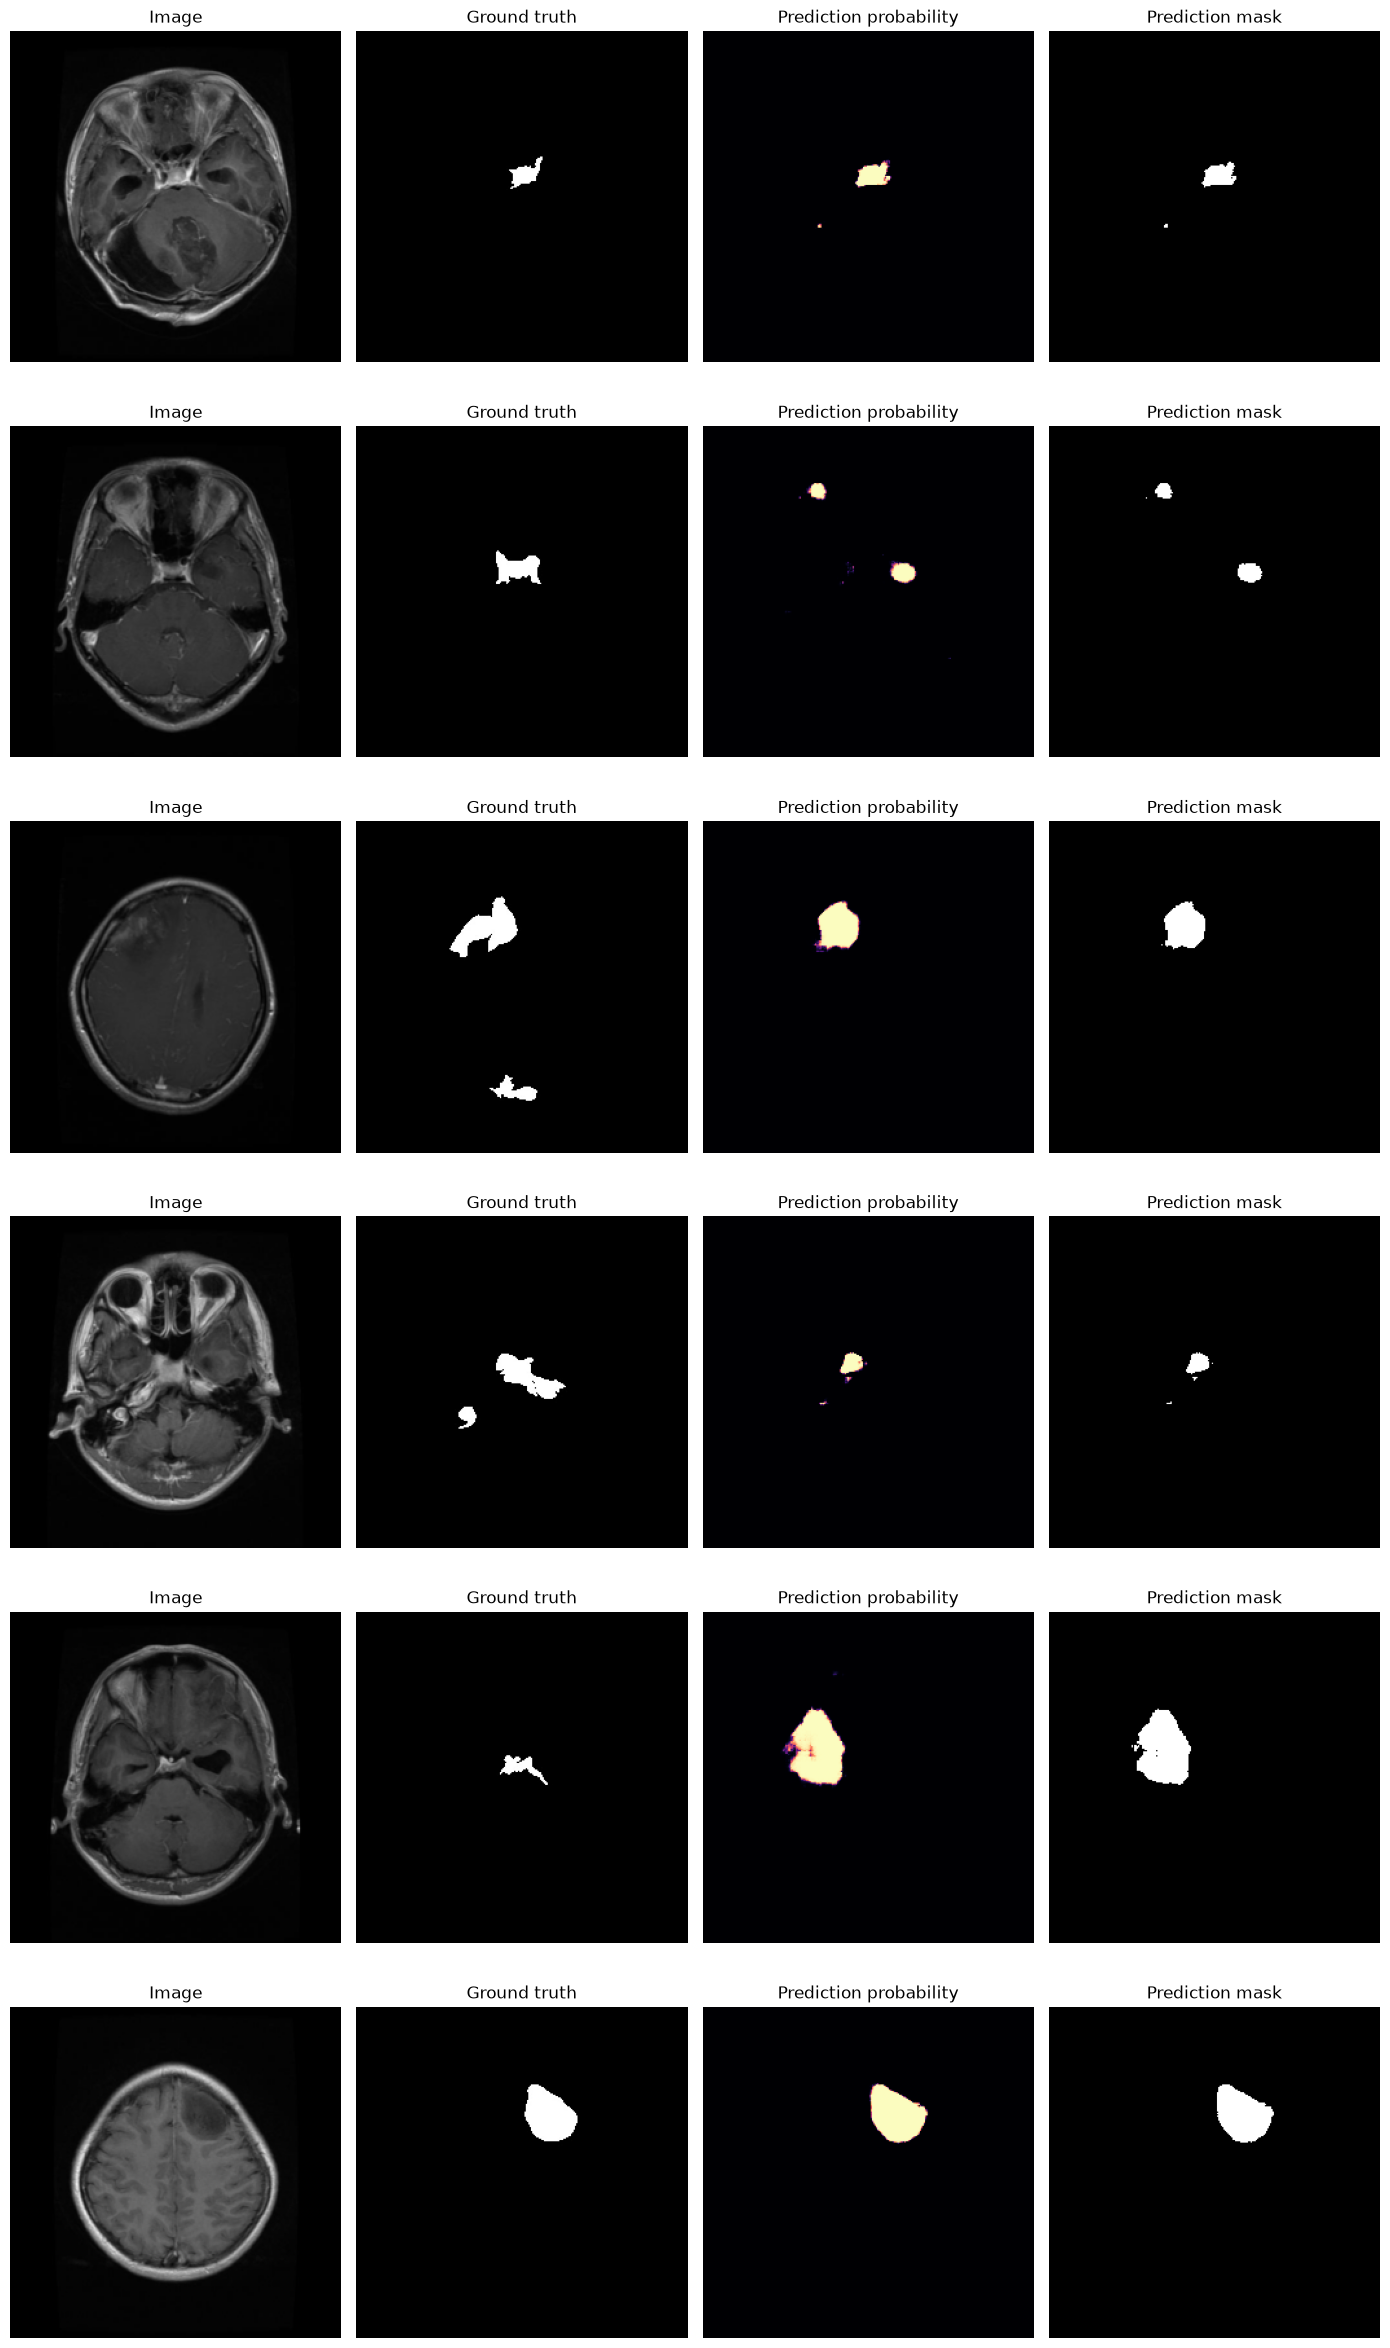

Validation IoU on 6 samples: {'class_0': 0.985414175634964, 'class_1': 0.3258569248855013}


In [16]:
from pathlib import Path

CHECKPOINT_DIR = Path('/Users/felixdelisle/Desktop/models/MobileUnetR/checkpoints')
BEST_CHECKPOINT = CHECKPOINT_DIR / 'best_model.pt'
CURRENT_CHECKPOINT = CHECKPOINT_DIR / 'current_model.pt'

if BEST_CHECKPOINT.exists():
    checkpoint_path = BEST_CHECKPOINT
elif CURRENT_CHECKPOINT.exists():
    checkpoint_path = CURRENT_CHECKPOINT
    print('best_model.pt was not found; using current_model.pt.')
else:
    raise FileNotFoundError(
        f'No checkpoint found in {CHECKPOINT_DIR}. Run the training cell first.'
    )

inference_model = MobileUNETR(in_channels=3, num_classes=1).to(DEVICE)
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
inference_model.load_state_dict(checkpoint['model_state_dict'])
inference_model.eval()

print(f'Loaded checkpoint: {checkpoint_path}')
print(f"Checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"Checkpoint validation loss: {checkpoint.get('val_loss', 'unknown')}")

sample_count = min(6, len(val_ds))
figure, axes = plt.subplots(sample_count, 4, figsize=(14, 4 * sample_count), squeeze=False)
validation_iou = {'class_0': 0.0, 'class_1': 0.0}

with torch.no_grad():
    for row, index in enumerate(range(sample_count)):
        image, target = val_ds[index]
        image_batch = image.unsqueeze(0).to(DEVICE, dtype=torch.float32)
        target_batch = target.unsqueeze(0).to(DEVICE, dtype=torch.float32)
        logits = inference_model(image_batch)
        prediction = (torch.sigmoid(logits) >= 0.5).float()

        sample_iou = compute_iou_per_class(logits, target_batch)
        for key in validation_iou:
            validation_iou[key] += sample_iou[key]

        axes[row, 0].imshow(image.permute(1, 2, 0).cpu().numpy())
        axes[row, 0].set_title('Image')
        axes[row, 1].imshow(target.squeeze().cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[row, 1].set_title('Ground truth')
        axes[row, 2].imshow(torch.sigmoid(logits).squeeze().cpu().numpy(), cmap='magma', vmin=0, vmax=1)
        axes[row, 2].set_title('Prediction probability')
        axes[row, 3].imshow(prediction.squeeze().cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[row, 3].set_title('Prediction mask')

        for column in range(4):
            axes[row, column].axis('off')

plt.tight_layout()
plt.show()

validation_iou = {key: value / sample_count for key, value in validation_iou.items()}
print(f'Validation IoU on {sample_count} samples: {validation_iou}')


### Export to ONNX